[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L6/BA_L6_refadj/BA_L6_refadj.ipynb)

# BA_L6_refadj: Effect of the reference adjustment

*Quantlet of Lecture 6, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Rolling 90-day standard deviations of the daily dollar return of STASIS Euro (EURS) and Pax Gold (PAXG), of their reference assets (EUR/USD, XAU/USD) and of the reference-adjusted return, January 2021 - May 2026 (EODHD data).

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

## Effect of the reference adjustment

**Reference adjustment.** Let $P_{i,t}$ be the dollar price of token $i$ and $B_{i,t}$ the dollar value of its reference asset ($B = 1$ for dollar tokens, EUR/USD for STASIS Euro (EURS), XAU/USD for Pax Gold (PAXG)). The reference-adjusted deviation, in basis points (bp, 0.01%), is
$$ d_{i,t} = 10^4\left(\frac{P_{i,t}}{B_{i,t}} - 1\right). $$
Prices are put on a calendar of all days and filled from the past for at most 7 days; a daily move beyond 1,000 bp that reverses by at least 90% the next day is treated as a recording error and removed.

The reference-adjusted return is $r_{i,t} = 10^4\,\Delta \ln (P_{i,t}/B_{i,t})$. If a token tracks its reference, $r_{i,t}$ is much calmer than its dollar return $10^4\,\Delta \ln P_{i,t}$.

**How to read the chart.** For EURS and PAXG, the 90-day standard deviation (in bp per day, log scale) of the token's dollar return (blue), of the reference's dollar return (gold, dashed) and of the reference-adjusted return (red), prices as recorded, January 2021 – May 2026.

In [4]:
# Data: 10 stablecoins, their reference assets and four market variables, 1 January 2020 - 23 October 2026
import matplotlib
plt.rcParams['font.size'] = 10
END, END_PAPER = '2026-10-23', '2026-05-31'          # last day of the lecture sample; last day of the paper's sample
COINS = ['USDT', 'USDC', 'DAI', 'TUSD', 'USDP', 'GUSD', 'BUSD', 'SUSD', 'PAXG', 'EURS']
cal = pd.date_range('2020-01-01', END)


def weekdays(x):
    """EUR/USD and gold: Monday-Friday closes, repeated closes removed (the weekend bars come from a thin session)."""
    x = x[x.index.dayofweek < 5]
    return x[x.diff() != 0]


def finish_fig(fig, name, bottom, ncol=3):
    """Legend below the plot, then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)


ref = {'EURS': weekdays(daily('EURUSD.FOREX', END)), 'PAXG': weekdays(daily('XAUUSD.FOREX', END))}
P = pd.DataFrame({c: daily(f'{c}-USD.CC', END) for c in COINS}).reindex(cal).ffill(limit=7)    # past-only fill, at most 7 days
lr = 1e4 * np.log(P).diff()
bad = (lr.abs() > 1000) & (-lr.shift(-1) / lr >= 0.9)      # bad print: a move beyond 1000 bp, reversed by >= 90% the next day
P_raw = P.copy()                                           # prices as recorded
P = P.mask(bad).ffill(limit=7)                             # retrospective cleaning
Bm = pd.DataFrame({c: (ref[c].reindex(cal).ffill() if c in ref else pd.Series(1.0, index=cal)) for c in COINS})
D = 1e4 * (P / Bm - 1)                                     # reference-adjusted deviation d (bp)
D_raw = 1e4 * (P_raw / Bm - 1)                             # same, prices as recorded
R = 1e4 * np.log(P / Bm).diff()                            # reference-adjusted log return (bp)
mac = pd.DataFrame({'DXY': daily('DXY.INDX', END), 'VIX': daily('VIX.INDX', END), 'SPX': daily('GSPC.INDX', END),
                    'US1Y': daily('US1Y.GBOND', END)}).reindex(cal).ffill()
M = pd.DataFrame({'DXY': np.log(mac['DXY']).diff(), 'VIX': np.log(mac['VIX']).diff(), 'SPX': np.log(mac['SPX']).diff(),
                  'US1Y': mac['US1Y'].diff()}).shift(1)     # market changes, lagged one day
print(f'calendar {cal[0].date()} to {cal[-1].date()} ({len(cal)} days); bad prints removed: {int(bad.values.sum())}')

calendar 2020-01-01 to 2026-10-23 (2488 days); bad prints removed: 9


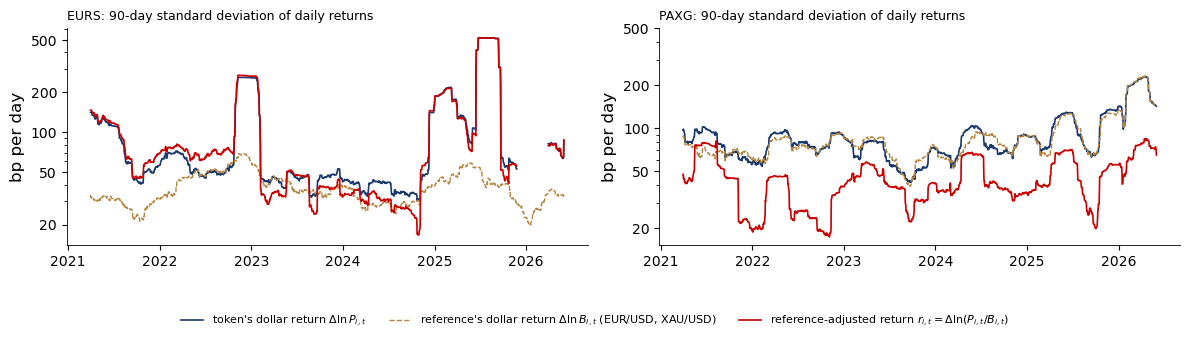

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
rows = {}
for j_, c in enumerate(['EURS', 'PAXG']):
    r_u = 1e4 * np.log(P_raw[c]).diff().loc['2021-01-01':END_PAPER]                 # token in USD
    r_b = 1e4 * np.log(Bm[c]).diff().loc['2021-01-01':END_PAPER]                    # reference in USD
    r_a = 1e4 * np.log(P_raw[c] / Bm[c]).diff().loc['2021-01-01':END_PAPER]         # reference-adjusted
    rows[c] = {'sd, token in USD (bp)': r_u.std(), 'sd, reference in USD (bp)': r_b.std(), 'sd, adjusted (bp)': r_a.std(),
               'correlation token-reference': r_u.corr(r_b)}
    ax[j_].plot(r_u.index, r_u.rolling(90).std(), color=BLUE, lw=1.2, label=(r"token's dollar return $\Delta \ln P_{i,t}$" if j_ == 0 else None))
    ax[j_].plot(r_b.index, r_b.rolling(90).std(), color=GOLD, lw=1.0, ls='--', label=(r"reference's dollar return $\Delta \ln B_{i,t}$ (EUR/USD, XAU/USD)" if j_ == 0 else None))
    ax[j_].plot(r_a.index, r_a.rolling(90).std(), color=RED, lw=1.2, label=(r'reference-adjusted return $r_{i,t} = \Delta \ln (P_{i,t}/B_{i,t})$' if j_ == 0 else None))
    ax[j_].set_title(f'{c}: 90-day standard deviation of daily returns', fontsize=9, loc='left')
    ax[j_].set_ylabel('bp per day'); ax[j_].set_yscale('log'); ax[j_].set_yticks([20, 50, 100, 200, 500])
    ax[j_].yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%g')); ax[j_].yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
finish_fig(fig, 'ba_l6_refadj', 0.15, ncol=3)

## Key numbers

In [6]:
r_e = 1e4 * np.log(Bm['EURS']).diff().loc['2021-01-01':END_PAPER]
big = r_e.abs().idxmax()
print(f'largest EUR/USD move: {big.date()}, {r_e.loc[big]:+.0f} bp; EURS in USD {1e4 * np.log(P_raw["EURS"]).diff().loc[big]:+.0f} bp, '
      f'against the euro {1e4 * np.log(P_raw["EURS"] / Bm["EURS"]).diff().loc[big]:+.0f} bp')
pd.DataFrame(rows).T.round(2)

largest EUR/USD move: 2025-04-10, +227 bp; EURS in USD +159 bp, against the euro -68 bp


,"sd, token in USD (bp)","sd, reference in USD (bp)","sd, adjusted (bp)",correlation token-reference
EURS,145.76,39.25,146.98,0.10
PAXG,95.85,93.58,47.53,0.87


**How to read it:** for PAXG the adjustment halves the noise (96 to 48 bp a day; correlation with gold 0.87). For EURS the token's own noise (146 bp a day, four times the euro's 39 bp; correlation 0.10) dominates, and the adjustment cannot remove it.